In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score , mean_absolute_error

In [ ]:
import pandas as pd

df = pd.read_csv("D:\AI-ML_class\MLR Data.csv",[]

)

df.head()

,Unnamed: 0,experience,age,skills_score,salary
0,0,7,31,55,115.740552
1,1,4,25,77,110.407407
2,2,13,31,77,161.582380
3,3,11,34,93,168.521428
4,4,8,30,93,143.577550


In [9]:
print("Missing values:",df.isnull().sum())
print("Duplicates :",df.duplicated().sum())


df = df.drop_duplicates()
print("Cleaned shape: ",df.shape)

Missing values: Unnamed: 0      0
experience      0
age             0
skills_score    0
salary          0
dtype: int64
Duplicates : 0
Cleaned shape:  (100, 5)


In [14]:

print("Correlation between salary and skills", round(df["salary"].corr(df["skills_score"]), 4))

print("Correlation between salary and experience", round(df["salary"].corr(df["experience"]), 4))

print("Correlation between salary and age", round(df["salary"].corr(df["age"]), 4))


Correlation between salary and skills 0.5274
Correlation between salary and experience 0.8882
Correlation between salary and age 0.7764


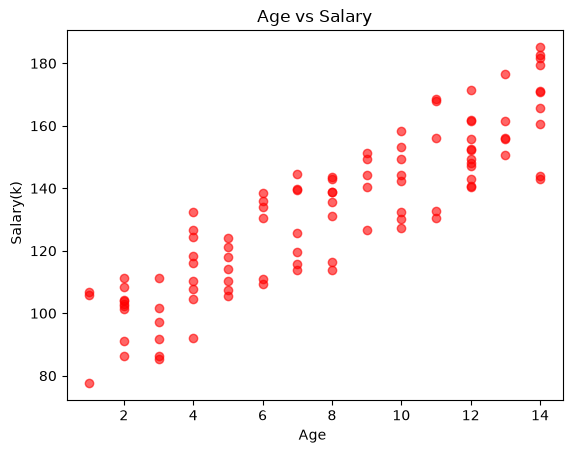

In [17]:
plt.Figure(figsize=(6,4))
plt.scatter(df['experience'],df['salary'],color='red',alpha=0.6)
plt.title("Age vs Salary")
plt.xlabel("Age ")
plt.ylabel(" Salary(k)")
plt.show()

In [ ]:
df.shape

(100, 5)

In [20]:
#Step 4: Train Model

x = df[['experience', 'age', 'skills_score']]

y=df['salary']

X_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.2, random_state=42)
print("\nTrain size:", X_train.shape[0], "| Test size:", x_test.shape[0])


Train size: 80 | Test size: 20


In [21]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[4.99,0.32,0.78]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['experience','age','skills_score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,26.38
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [22]:
y_pred = model.predict(x_test)

In [23]:
print("\nModel Performance:")

print(" R2 Score:", round(r2_score(y_test, y_pred), 4))

print(" MAE", round(mean_absolute_error(y_test, y_pred), 2))


Model Performance:
 R2 Score: 0.9818
 MAE 2.61


In [24]:
unseen = pd. DataFrame({

'experience':

[3, 8, 12],

'age':

[25, 33, 40],

'skills_score':

[60, 80, 95]

})

predictions = model.predict(unseen)

unseen ['Predicted Salary'] = predictions.round(2)

print(unseen)

   experience  age  skills_score  Predicted Salary
0           3   25            60             96.15
1           8   33            80            139.25
2          12   40            95            173.15
